# Economic Simulation of Smart EV Charging

## The Economic Value of Smart EV Charging

**Market:** Germany–Luxembourg Day-Ahead Market

**Observation period:** 2025

**Data source:** Fraunhofer ISE Energy-Charts API
(Bundesnetzagentur SMARD)

**Temporal resolution:** Hourly

---

## Research objective

This notebook investigates the achievable economic
benefits of alternative electric vehicle charging
strategies using historical electricity prices.

Three charging strategies are compared:

1. Immediate charging upon connection.
2. Fixed-time charging beginning at midnight.
3. Dynamic charging during the cheapest feasible periods.

The analysis uses a hypothetical electric vehicle
calibrated with technical and consumption parameters
from Lohr et al. (2025).

All strategies face identical energy requirements,
charging power limits and mobility requirements.

The simulation estimates conditional charging cost
savings rather than observed household savings.

The analysis focuses exclusively on unidirectional,
market-driven residential EV charging.

## 1. Environment Setup and Data Loading

The validated hourly electricity price dataset is
imported from the processed data directory.

The simulation uses timezone-aware timestamps to
ensure correct chronological treatment of overnight
charging sessions and daylight-saving transitions.

In [22]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Identify project root
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

# Define directories
processed_dir = project_root / "data" / "processed"
figures_dir = project_root / "outputs" / "figures"
tables_dir = project_root / "outputs" / "tables"

figures_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

# Load validated electricity prices
data_path = (
    processed_dir / "DE_LU_day_ahead_2025_hourly.csv"
)

df_hourly = pd.read_csv(data_path)

# Restore timezone-aware timestamps
df_hourly["timestamp_utc"] = pd.to_datetime(
    df_hourly["timestamp_utc"],
    utc=True
)

df_hourly["timestamp_local"] = (
    df_hourly["timestamp_utc"]
    .dt.tz_convert("Europe/Berlin")
)

df_hourly = (
    df_hourly
    .sort_values("timestamp_utc")
    .reset_index(drop=True)
)

# Validate imported dataset
assert len(df_hourly) == 8760
assert df_hourly.isna().sum().sum() == 0
assert df_hourly["timestamp_utc"].is_unique
assert np.isfinite(df_hourly["price_eur_mwh"]).all()

# Verify complete hourly coverage
expected_index = pd.date_range(
    start="2025-01-01",
    end="2026-01-01",
    freq="h",
    inclusive="left",
    tz="Europe/Berlin"
).tz_convert("UTC")

assert (
    pd.DatetimeIndex(df_hourly["timestamp_utc"])
    == expected_index
).all()

print("Electricity price dataset successfully loaded.")
print("Observations:", len(df_hourly))
print("All integrity checks passed.")

display(df_hourly.head())

Electricity price dataset successfully loaded.
Observations: 8760
All integrity checks passed.


,timestamp_utc,price_eur_mwh,source_observations,timestamp_local,price_eur_kwh
0,2024-12-31 23:00:00+00:00,2.16,1,2025-01-01 00:00:00+01:00,0.00216
1,2025-01-01 00:00:00+00:00,1.60,1,2025-01-01 01:00:00+01:00,0.00160
2,2025-01-01 01:00:00+00:00,0.00,1,2025-01-01 02:00:00+01:00,0.00000
3,2025-01-01 02:00:00+00:00,-0.01,1,2025-01-01 03:00:00+01:00,-0.00001
4,2025-01-01 03:00:00+00:00,-0.01,1,2025-01-01 04:00:00+01:00,-0.00001


## 2. Model Parameters

The reference vehicle is calibrated using Lohr et al.
(2025, pp. 6–7 and 11).

Annual residential grid electricity consumption is
set to 1,584 kWh, corresponding to the explicitly
reported residential electricity consumption in
their reference case.

Charging losses are not added again to this grid
electricity requirement.

The model assumes evenly distributed daily energy
requirements and identical daily charging targets.

Arrival and departure times are hypothetical
research scenarios rather than observed mobility
profiles.

In [23]:
# Literature-based vehicle parameters
BATTERY_CAPACITY_KWH = 45.0
MAX_CHARGING_POWER_KW = 11.0
ANNUAL_HOME_GRID_ENERGY_KWH = 1584.0
CHARGING_EFFICIENCY = 0.95
TARGET_SOC = 0.60

# Simulation parameters
DAYS_PER_YEAR = 365
TIME_STEP_HOURS = 1.0

# Hypothetical charging availability
ARRIVAL_HOUR = 18
DEPARTURE_HOUR = 6

# Fixed-time strategy
FIXED_CHARGING_HOUR = 0

# Illustrative retail tariff assumptions
FLAT_TARIFF_EUR_KWH = 0.30
CONSTANT_CHARGES_EUR_KWH = 0.20

# Calculate daily grid energy demand
DAILY_GRID_ENERGY_KWH = (
    ANNUAL_HOME_GRID_ENERGY_KWH
    / DAYS_PER_YEAR
)

# Electricity stored in the battery
DAILY_BATTERY_ENERGY_KWH = (
    DAILY_GRID_ENERGY_KWH
    * CHARGING_EFFICIENCY
)

# Charging duration at maximum power
CHARGING_DURATION_HOURS = (
    DAILY_GRID_ENERGY_KWH
    / MAX_CHARGING_POWER_KW
)

# Battery energy at departure
TARGET_BATTERY_ENERGY_KWH = (
    BATTERY_CAPACITY_KWH
    * TARGET_SOC
)

# Implied arrival battery energy
ARRIVAL_BATTERY_ENERGY_KWH = (
    TARGET_BATTERY_ENERGY_KWH
    - DAILY_BATTERY_ENERGY_KWH
)

ARRIVAL_SOC = (
    ARRIVAL_BATTERY_ENERGY_KWH
    / BATTERY_CAPACITY_KWH
)

# Display model parameters
parameters = pd.Series({
    "Battery capacity (kWh)": BATTERY_CAPACITY_KWH,
    "Maximum charging power (kW)": MAX_CHARGING_POWER_KW,
    "Annual home grid energy (kWh)": ANNUAL_HOME_GRID_ENERGY_KWH,
    "Daily grid energy (kWh)": DAILY_GRID_ENERGY_KWH,
    "Daily battery energy (kWh)": DAILY_BATTERY_ENERGY_KWH,
    "Charging efficiency (%)": CHARGING_EFFICIENCY * 100,
    "Minimum charging duration (min)": CHARGING_DURATION_HOURS * 60,
    "Arrival SOC (%)": ARRIVAL_SOC * 100,
    "Departure SOC (%)": TARGET_SOC * 100
}, name="Value")

display(parameters.to_frame().round(4))

# Validate battery assumptions
assert 0 <= ARRIVAL_SOC <= TARGET_SOC <= 1

assert (
    ARRIVAL_BATTERY_ENERGY_KWH
    + DAILY_BATTERY_ENERGY_KWH
    <= BATTERY_CAPACITY_KWH
)

,Value
Battery capacity (kWh),45.0000
Maximum charging power (kW),11.0000
Annual home grid energy (kWh),1584.0000
Daily grid energy (kWh),4.3397
Daily battery energy (kWh),4.1227
Charging efficiency (%),95.0000
Minimum charging duration (min),23.6712
Arrival SOC (%),50.8384
Departure SOC (%),60.0000


## 3. Construction of Overnight Charging Sessions

Each charging session begins at 18:00 local time
and ends at 06:00 on the following calendar day.

Sessions are constructed using timezone-aware
timestamps to account for daylight-saving transitions.

Only complete overnight sessions contained within
the validated 2025 dataset are included.

Consequently, 364 charging sessions are simulated.
The final session beginning on 31 December is
excluded because it extends beyond the dataset.

Annual estimates are calculated by scaling the
364-session results to 365 equivalent sessions.
These are annualised model estimates rather than
exact full-calendar-year expenditure.

In [24]:
# Create a lookup table indexed by UTC timestamps
price_lookup = (
    df_hourly
    .set_index("timestamp_utc")
    ["price_eur_kwh"]
)

# Define complete overnight session arrival dates
session_dates = pd.date_range(
    start="2025-01-01",
    end="2025-12-30",
    freq="D"
)

session_records = []

# Construct every complete overnight session
for date in session_dates:

    # Construct boundaries in local wall-clock time
    arrival = (
        date
        + pd.Timedelta(hours=ARRIVAL_HOUR)
    ).tz_localize("Europe/Berlin")

    departure = (
        date
        + pd.Timedelta(days=1)
        + pd.Timedelta(hours=DEPARTURE_HOUR)
    ).tz_localize("Europe/Berlin")

    # Generate feasible hourly charging intervals
    timestamps = pd.date_range(
        start=arrival,
        end=departure,
        freq="h",
        inclusive="left"
    )

    timestamps_utc = timestamps.tz_convert("UTC")

    # Retrieve corresponding electricity prices
    session_prices = price_lookup.reindex(
        timestamps_utc
    )

    # Ensure complete price coverage
    assert session_prices.notna().all()

    session = pd.DataFrame({
        "session_id": date.strftime("%Y-%m-%d"),
        "timestamp_utc": timestamps_utc,
        "timestamp_local": timestamps,
        "price_eur_kwh": session_prices.to_numpy()
    })

    session["hour"] = (
        session["timestamp_local"].dt.hour
    )

    session["interval_hours"] = TIME_STEP_HOURS

    session_records.append(session)

# Combine all charging sessions
sessions = pd.concat(
    session_records,
    ignore_index=True
)

# Calculate session lengths
session_lengths = (
    sessions.groupby("session_id")
    .size()
)

# Validate session construction
assert len(session_lengths) == 364
assert sessions["timestamp_utc"].is_unique
assert session_lengths.isin([11, 12, 13]).all()

assert (
    sessions["hour"].ge(18)
    | sessions["hour"].lt(6)
).all()

print("Complete charging sessions:", len(session_lengths))
print("Available charging intervals:", len(sessions))

print("\nDistribution of session lengths:")
print(session_lengths.value_counts().sort_index())

print("\nFirst session:")
display(
    sessions[
        sessions["session_id"] == "2025-01-01"
    ]
)

Complete charging sessions: 364
Available charging intervals: 4368

Distribution of session lengths:
11      1
12    362
13      1
Name: count, dtype: int64

First session:


,session_id,timestamp_utc,timestamp_local,price_eur_kwh,hour,interval_hours
0,2025-01-01,2025-01-01 17:00:00+00:00,2025-01-01 18:00:00+01:00,0.00101,18,1.0
1,2025-01-01,2025-01-01 18:00:00+00:00,2025-01-01 19:00:00+01:00,0.00148,19,1.0
2,2025-01-01,2025-01-01 19:00:00+00:00,2025-01-01 20:00:00+01:00,0.00100,20,1.0
3,2025-01-01,2025-01-01 20:00:00+00:00,2025-01-01 21:00:00+01:00,0.00007,21,1.0
4,2025-01-01,2025-01-01 21:00:00+00:00,2025-01-01 22:00:00+01:00,0.01005,22,1.0
5,2025-01-01,2025-01-01 22:00:00+00:00,2025-01-01 23:00:00+01:00,0.00701,23,1.0
6,2025-01-01,2025-01-01 23:00:00+00:00,2025-01-02 00:00:00+01:00,0.00255,0,1.0
7,2025-01-01,2025-01-02 00:00:00+00:00,2025-01-02 01:00:00+01:00,0.00156,1,1.0
8,2025-01-01,2025-01-02 01:00:00+00:00,2025-01-02 02:00:00+01:00,0.00345,2,1.0
9,2025-01-01,2025-01-02 02:00:00+00:00,2025-01-02 03:00:00+01:00,0.00702,3,1.0


## 4. Implementation of Charging Strategies

A common energy allocation function is used to
compare alternative charging strategies.

Immediate charging prioritises the earliest
available interval.

Fixed-time charging prioritises chronological
intervals beginning at midnight.

Dynamic charging prioritises intervals in ascending
order of day-ahead electricity prices.

All strategies must deliver the same quantity of
grid electricity and respect maximum charging power.

Partial utilisation of an hourly interval is permitted.
Electricity expenditure is calculated using the
corresponding hourly average price.

In [25]:
def allocate_charging(
    session,
    strategy,
    energy_required=DAILY_GRID_ENERGY_KWH,
    max_power=MAX_CHARGING_POWER_KW
):
    """
    Allocate grid electricity within a charging session.

    Returns the complete charging schedule, including
    charging quantities, electricity costs and battery
    state of charge.
    """

    schedule = (
        session
        .sort_values("timestamp_utc")
        .reset_index(drop=True)
        .copy()
    )

    # Initialise charging quantities
    schedule["charging_kwh"] = 0.0

    # Determine interval priority
    if strategy == "Immediate":

        priority = schedule.index.to_list()

    elif strategy == "Fixed-time":

        eligible = schedule[
            (schedule["hour"] >= FIXED_CHARGING_HOUR)
            & (schedule["hour"] < DEPARTURE_HOUR)
        ]

        priority = eligible.index.to_list()

    elif strategy == "Dynamic":

        priority = (
            schedule.sort_values(
                ["price_eur_kwh", "timestamp_utc"]
            )
            .index.to_list()
        )

    else:

        raise ValueError(
            f"Unknown charging strategy: {strategy}"
        )

    # Allocate electricity in the chosen priority order
    remaining_energy = float(energy_required)

    for idx in priority:

        if remaining_energy <= 1e-10:
            break

        interval_capacity = (
            max_power
            * schedule.loc[idx, "interval_hours"]
        )

        charged_energy = min(
            remaining_energy,
            interval_capacity
        )

        schedule.loc[
            idx, "charging_kwh"
        ] = charged_energy

        remaining_energy -= charged_energy

    # Verify feasibility
    if remaining_energy > 1e-8:

        raise ValueError(
            f"Infeasible charging session: "
            f"{strategy}, "
            f"{remaining_energy:.4f} kWh unmet."
        )

    # Calculate electricity costs
    schedule["spot_cost_eur"] = (
        schedule["charging_kwh"]
        * schedule["price_eur_kwh"]
    )

    # Illustrative dynamic residential tariff
    schedule["retail_price_eur_kwh"] = (
        schedule["price_eur_kwh"]
        + CONSTANT_CHARGES_EUR_KWH
    )

    schedule["retail_cost_eur"] = (
        schedule["charging_kwh"]
        * schedule["retail_price_eur_kwh"]
    )

    # Calculate battery state of charge
    initial_battery_energy = (
        TARGET_BATTERY_ENERGY_KWH
        - energy_required * CHARGING_EFFICIENCY
    )

    if initial_battery_energy < -1e-8:
        raise ValueError(
            "Energy requirement incompatible with "
            "the assumed battery target."
        )

    schedule["battery_energy_kwh"] = (
        initial_battery_energy
        + (
            schedule["charging_kwh"]
            * CHARGING_EFFICIENCY
        ).cumsum()
    )

    schedule["soc_pct"] = (
        schedule["battery_energy_kwh"]
        / BATTERY_CAPACITY_KWH
        * 100
    )

    schedule["strategy"] = strategy

    return schedule

## 5. Model Testing

The charging allocation function is initially
evaluated using a single historical overnight
charging session.

The test verifies that all strategies deliver
identical electricity quantities, respect charging
power limits, achieve the target battery state of
charge and satisfy the departure deadline.

The dynamic strategy is additionally checked
against a mathematically known cost-minimisation
benchmark.

In [26]:
# Select the first complete historical session
test_session = sessions[
    sessions["session_id"] == "2025-01-01"
].copy()

strategies = [
    "Immediate",
    "Fixed-time",
    "Dynamic"
]

test_results = []

# Run all three strategies
for strategy in strategies:

    result = allocate_charging(
        test_session,
        strategy
    )

    test_results.append(result)

# Combine results
test_results = pd.concat(
    test_results,
    ignore_index=True
)

# Display charging intervals
display(
    test_results.loc[
        test_results["charging_kwh"] > 0,
        [
            "strategy",
            "timestamp_local",
            "price_eur_kwh",
            "charging_kwh",
            "spot_cost_eur",
            "retail_cost_eur",
            "soc_pct"
        ]
    ].round(4)
)

# Summarise the session
test_summary = (
    test_results
    .groupby("strategy", sort=False)
    .agg(
        energy_kwh=("charging_kwh", "sum"),
        spot_cost_eur=("spot_cost_eur", "sum"),
        retail_cost_eur=("retail_cost_eur", "sum"),
        final_soc_pct=("soc_pct", "last")
    )
)

display(test_summary.round(4))

/var/folders/xc/v09c66cx1rb50f6bqk87k7th0000gn/T/ipykernel_73993/3605117473.py:43: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(4)


,strategy,timestamp_local,price_eur_kwh,charging_kwh,spot_cost_eur,retail_cost_eur,soc_pct
0,Immediate,2025-01-01 18:00:00+01:00,0.0010,4.3397,0.0044,0.8723,60.0
18,Fixed-time,2025-01-02 00:00:00+01:00,0.0025,4.3397,0.0111,0.8790,60.0
27,Dynamic,2025-01-01 21:00:00+01:00,0.0001,4.3397,0.0003,0.8682,60.0


,energy_kwh,spot_cost_eur,retail_cost_eur,final_soc_pct
strategy,,,,
Immediate,4.3397,0.0044,0.8723,60.0
Fixed-time,4.3397,0.0111,0.8790,60.0
Dynamic,4.3397,0.0003,0.8682,60.0


#### 5.2 Automated validation checks

In [27]:
# All strategies must deliver identical energy
assert np.allclose(
    test_summary["energy_kwh"],
    DAILY_GRID_ENERGY_KWH
)

# No negative charging quantities
assert (
    test_results["charging_kwh"] >= 0
).all()

# Maximum charging power respected
assert (
    test_results["charging_kwh"]
    <= MAX_CHARGING_POWER_KW
    * test_results["interval_hours"]
    + 1e-8
).all()

# Battery capacity respected
assert (
    test_results["soc_pct"] >= -1e-8
).all()

assert (
    test_results["soc_pct"] <= 100 + 1e-8
).all()

# All strategies restore the target SOC
assert np.allclose(
    test_summary["final_soc_pct"],
    TARGET_SOC * 100
)

# Dynamic charging cannot cost more than
# another feasible charging strategy
assert (
    test_summary.loc["Dynamic", "spot_cost_eur"]
    <= test_summary.loc["Immediate", "spot_cost_eur"]
    + 1e-8
)

assert (
    test_summary.loc["Dynamic", "spot_cost_eur"]
    <= test_summary.loc["Fixed-time", "spot_cost_eur"]
    + 1e-8
)

# At the reference charging power, the entire
# daily requirement fits within one hourly interval
assert (
    DAILY_GRID_ENERGY_KWH
    <= MAX_CHARGING_POWER_KW * TIME_STEP_HOURS
)

# Independently calculate the theoretical minimum
expected_minimum_cost = (
    test_session["price_eur_kwh"].min()
    * DAILY_GRID_ENERGY_KWH
)

assert np.isclose(
    test_summary.loc["Dynamic", "spot_cost_eur"],
    expected_minimum_cost
)

print("All single-session validation checks passed.")

All single-session validation checks passed.


#### 5.3 Test allocation with a known mathematical solution

In [28]:
# Construct a hypothetical session
synthetic_session = test_session.copy()

# Set all prices to 20 ct/kWh
synthetic_session["price_eur_kwh"] = 0.20

# Introduce two cheaper intervals
synthetic_session.loc[
    synthetic_session.index[0],
    "price_eur_kwh"
] = 0.10

synthetic_session.loc[
    synthetic_session.index[1],
    "price_eur_kwh"
] = 0.05

# Require 5 kWh at a maximum charging power of 3 kW
synthetic_result = allocate_charging(
    synthetic_session,
    strategy="Dynamic",
    energy_required=5.0,
    max_power=3.0
)

# Known analytical solution:
# 3 kWh at 0.05 EUR/kWh
# 2 kWh at 0.10 EUR/kWh

analytical_cost = (
    3 * 0.05
    + 2 * 0.10
)

simulated_cost = (
    synthetic_result["spot_cost_eur"].sum()
)

assert np.isclose(
    simulated_cost,
    analytical_cost
)

assert np.isclose(
    synthetic_result["charging_kwh"].sum(),
    5.0
)

print(f"Analytical cost: EUR {analytical_cost:.4f}")
print(f"Simulated cost: EUR {simulated_cost:.4f}")
print("Synthetic optimisation test passed.")

Analytical cost: EUR 0.3500
Simulated cost: EUR 0.3500
Synthetic optimisation test passed.


## 6. Annual Charging Simulation

Following successful validation of the charging
allocation algorithm, all three charging strategies
are applied to the 364 complete overnight charging
sessions available within the 2025 dataset.

Each strategy faces identical electricity demand,
charging power constraints, vehicle availability
and departure state-of-charge requirements.

The simulation produces interval-level charging
schedules and session-level electricity expenditures.

Annualised results are calculated by scaling the
364-session expenditure to 365 equivalent sessions.

These results represent simulated economic outcomes
conditional on the specified model assumptions,
rather than observed consumer expenditure.

In [29]:
# Define charging strategies
strategies = [
    "Immediate",
    "Fixed-time",
    "Dynamic"
]

# Initialise simulation results
simulation_records = []

# Simulate every charging session
for session_id, session in sessions.groupby(
    "session_id",
    sort=True
):

    for strategy in strategies:

        result = allocate_charging(
            session=session,
            strategy=strategy
        )

        simulation_records.append(result)

# Combine all interval-level results
simulation = pd.concat(
    simulation_records,
    ignore_index=True
)

# Ensure chronological order within each strategy
simulation = (
    simulation
    .sort_values([
        "session_id",
        "strategy",
        "timestamp_utc"
    ])
    .reset_index(drop=True)
)

print("Charging simulation completed.")
print("Charging strategies:", len(strategies))
print("Simulated sessions:", simulation["session_id"].nunique())
print("Strategy-session combinations:", len(simulation_records))
print("Interval-level observations:", len(simulation))

display(simulation.head())

Charging simulation completed.
Charging strategies: 3
Simulated sessions: 364
Strategy-session combinations: 1092
Interval-level observations: 13104


,session_id,timestamp_utc,timestamp_local,price_eur_kwh,hour,interval_hours,charging_kwh,spot_cost_eur,retail_price_eur_kwh,retail_cost_eur,battery_energy_kwh,soc_pct,strategy
0,2025-01-01,2025-01-01 17:00:00+00:00,2025-01-01 18:00:00+01:00,0.00101,18,1.0,0.000000,0.000000,0.20101,0.000000,22.87726,50.838356,Dynamic
1,2025-01-01,2025-01-01 18:00:00+00:00,2025-01-01 19:00:00+01:00,0.00148,19,1.0,0.000000,0.000000,0.20148,0.000000,22.87726,50.838356,Dynamic
2,2025-01-01,2025-01-01 19:00:00+00:00,2025-01-01 20:00:00+01:00,0.00100,20,1.0,0.000000,0.000000,0.20100,0.000000,22.87726,50.838356,Dynamic
3,2025-01-01,2025-01-01 20:00:00+00:00,2025-01-01 21:00:00+01:00,0.00007,21,1.0,4.339726,0.000304,0.20007,0.868249,27.00000,60.000000,Dynamic
4,2025-01-01,2025-01-01 21:00:00+00:00,2025-01-01 22:00:00+01:00,0.01005,22,1.0,0.000000,0.000000,0.21005,0.000000,27.00000,60.000000,Dynamic


#### 6.1 Aggregate session-level results

In [30]:
# Calculate flat-tariff charging costs
simulation["flat_cost_eur"] = (
    simulation["charging_kwh"]
    * FLAT_TARIFF_EUR_KWH
)

# Aggregate interval-level results
session_summary = (
    simulation
    .groupby(
        ["session_id", "strategy"],
        sort=False
    )
    .agg(
        energy_kwh=("charging_kwh", "sum"),
        spot_cost_eur=("spot_cost_eur", "sum"),
        retail_cost_eur=("retail_cost_eur", "sum"),
        flat_cost_eur=("flat_cost_eur", "sum"),
        final_soc_pct=("soc_pct", "last"),
        available_hours=("interval_hours", "sum")
    )
    .reset_index()
)

# Convert session IDs into dates
session_summary["date"] = pd.to_datetime(
    session_summary["session_id"]
)

# Calculate effective charging price
session_summary["average_spot_price_ct_kwh"] = (
    session_summary["spot_cost_eur"]
    / session_summary["energy_kwh"]
    * 100
)

session_summary["average_retail_price_ct_kwh"] = (
    session_summary["retail_cost_eur"]
    / session_summary["energy_kwh"]
    * 100
)

display(session_summary.head(9).round(4))

/var/folders/xc/v09c66cx1rb50f6bqk87k7th0000gn/T/ipykernel_73993/1768100452.py:43: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(session_summary.head(9).round(4))


,session_id,strategy,energy_kwh,spot_cost_eur,retail_cost_eur,flat_cost_eur,final_soc_pct,available_hours,date,average_spot_price_ct_kwh,average_retail_price_ct_kwh
0,2025-01-01,Dynamic,4.3397,0.0003,0.8682,1.3019,60.0,12.0,2025-01-01,0.007,20.007
1,2025-01-01,Fixed-time,4.3397,0.0111,0.8790,1.3019,60.0,12.0,2025-01-01,0.255,20.255
2,2025-01-01,Immediate,4.3397,0.0044,0.8723,1.3019,60.0,12.0,2025-01-01,0.101,20.101
3,2025-01-02,Dynamic,4.3397,0.3363,1.2043,1.3019,60.0,12.0,2025-01-02,7.750,27.750
4,2025-01-02,Fixed-time,4.3397,0.4321,1.3000,1.3019,60.0,12.0,2025-01-02,9.956,29.956
5,2025-01-02,Immediate,4.3397,0.6637,1.5317,1.3019,60.0,12.0,2025-01-02,15.294,35.294
6,2025-01-03,Dynamic,4.3397,0.3844,1.2523,1.3019,60.0,12.0,2025-01-03,8.857,28.857
7,2025-01-03,Fixed-time,4.3397,0.3924,1.2604,1.3019,60.0,12.0,2025-01-03,9.043,29.043
8,2025-01-03,Immediate,4.3397,0.4993,1.3673,1.3019,60.0,12.0,2025-01-03,11.506,31.506


#### 6.2 Validate the entire simulation

In [31]:
TOLERANCE = 1e-8

# Verify simulation dimensions
assert len(session_summary) == 364 * 3
assert len(simulation) == 4368 * 3

# Verify identical energy requirements
assert np.allclose(
    session_summary["energy_kwh"],
    DAILY_GRID_ENERGY_KWH
)

# Verify final state of charge
assert np.allclose(
    session_summary["final_soc_pct"],
    TARGET_SOC * 100
)

# Verify non-negative charging quantities
assert (
    simulation["charging_kwh"] >= -TOLERANCE
).all()

# Verify charging power constraints
assert (
    simulation["charging_kwh"]
    <= MAX_CHARGING_POWER_KW
    * simulation["interval_hours"]
    + TOLERANCE
).all()

# Verify battery capacity
assert simulation["soc_pct"].between(
    0 - TOLERANCE,
    100 + TOLERANCE
).all()

# Compare session costs across strategies
cost_comparison = session_summary.pivot(
    index="session_id",
    columns="strategy",
    values="spot_cost_eur"
)

# Dynamic optimisation must not cost more
# than another feasible charging strategy
assert (
    cost_comparison["Dynamic"]
    <= cost_comparison["Immediate"] + TOLERANCE
).all()

assert (
    cost_comparison["Dynamic"]
    <= cost_comparison["Fixed-time"] + TOLERANCE
).all()

# Verify identical flat-tariff expenditure
flat_comparison = session_summary.pivot(
    index="session_id",
    columns="strategy",
    values="flat_cost_eur"
)

assert np.allclose(
    flat_comparison["Immediate"],
    flat_comparison["Dynamic"]
)

assert np.allclose(
    flat_comparison["Immediate"],
    flat_comparison["Fixed-time"]
)

# Verify finite numerical results
assert np.isfinite(
    simulation[
        [
            "charging_kwh",
            "spot_cost_eur",
            "retail_cost_eur",
            "soc_pct"
        ]
    ].to_numpy()
).all()

print("All annual simulation validation checks passed.")

All annual simulation validation checks passed.


## 7. Annual Economic Results

Annual electricity expenditure is calculated for
each charging strategy under three pricing scenarios:

1. Wholesale electricity prices.
2. An illustrative dynamic residential tariff.
3. A constant residential tariff.

All expenditure estimates are annualised from
364 complete charging sessions to 365 equivalent
sessions.

Absolute and relative cost savings are calculated
against immediate charging.

The wholesale-only scenario isolates the economic
value of timing, while the dynamic residential tariff
illustrates the effect of constant non-wholesale
price components on consumer expenditure.

#### 7.1 Annualised charging costs

In [32]:
# Annualisation factor
ANNUALISATION_FACTOR = (
    DAYS_PER_YEAR
    / session_summary["session_id"].nunique()
)

# Aggregate total simulated expenditure
annual_summary = (
    session_summary
    .groupby("strategy")
    .agg(
        sessions=("session_id", "count"),
        simulated_energy_kwh=("energy_kwh", "sum"),
        simulated_spot_cost_eur=("spot_cost_eur", "sum"),
        simulated_retail_cost_eur=("retail_cost_eur", "sum"),
        simulated_flat_cost_eur=("flat_cost_eur", "sum")
    )
    .reindex(strategies)
)

# Annualise energy demand and expenditure
annual_summary["annual_energy_kwh"] = (
    annual_summary["simulated_energy_kwh"]
    * ANNUALISATION_FACTOR
)

annual_summary["annual_spot_cost_eur"] = (
    annual_summary["simulated_spot_cost_eur"]
    * ANNUALISATION_FACTOR
)

annual_summary["annual_retail_cost_eur"] = (
    annual_summary["simulated_retail_cost_eur"]
    * ANNUALISATION_FACTOR
)

annual_summary["annual_flat_cost_eur"] = (
    annual_summary["simulated_flat_cost_eur"]
    * ANNUALISATION_FACTOR
)

# Calculate average effective charging prices
annual_summary["average_spot_price_ct_kwh"] = (
    annual_summary["annual_spot_cost_eur"]
    / annual_summary["annual_energy_kwh"]
    * 100
)

annual_summary["average_retail_price_ct_kwh"] = (
    annual_summary["annual_retail_cost_eur"]
    / annual_summary["annual_energy_kwh"]
    * 100
)

# Verify annualised energy consumption
assert np.allclose(
    annual_summary["annual_energy_kwh"],
    ANNUAL_HOME_GRID_ENERGY_KWH
)

# Display annualised results
display(
    annual_summary[
        [
            "annual_energy_kwh",
            "annual_spot_cost_eur",
            "annual_retail_cost_eur",
            "annual_flat_cost_eur",
            "average_spot_price_ct_kwh",
            "average_retail_price_ct_kwh"
        ]
    ].round(2)
)

,annual_energy_kwh,annual_spot_cost_eur,annual_retail_cost_eur,annual_flat_cost_eur,average_spot_price_ct_kwh,average_retail_price_ct_kwh
strategy,,,,,,
Immediate,1584.0,196.81,513.61,475.2,12.43,32.43
Fixed-time,1584.0,141.12,457.92,475.2,8.91,28.91
Dynamic,1584.0,121.13,437.93,475.2,7.65,27.65


#### 7.2 Calculate absolute and relative savings

In [33]:
# Reference costs
baseline_spot_cost = annual_summary.loc[
    "Immediate", "annual_spot_cost_eur"
]

baseline_retail_cost = annual_summary.loc[
    "Immediate", "annual_retail_cost_eur"
]

# Absolute wholesale savings
annual_summary["spot_savings_eur"] = (
    baseline_spot_cost
    - annual_summary["annual_spot_cost_eur"]
)

# Absolute retail savings
annual_summary["retail_savings_eur"] = (
    baseline_retail_cost
    - annual_summary["annual_retail_cost_eur"]
)

# Relative wholesale savings
annual_summary["spot_savings_pct"] = (
    annual_summary["spot_savings_eur"]
    / baseline_spot_cost
    * 100
    if baseline_spot_cost > 0
    else np.nan
)

# Relative retail savings
annual_summary["retail_savings_pct"] = (
    annual_summary["retail_savings_eur"]
    / baseline_retail_cost
    * 100
    if baseline_retail_cost > 0
    else np.nan
)

# Verify constant tariff charges cancel
assert np.allclose(
    annual_summary["spot_savings_eur"],
    annual_summary["retail_savings_eur"]
)

# Display main economic results
economic_results = annual_summary[
    [
        "annual_spot_cost_eur",
        "annual_retail_cost_eur",
        "spot_savings_eur",
        "spot_savings_pct",
        "retail_savings_eur",
        "retail_savings_pct"
    ]
]

display(economic_results.round(2))

,annual_spot_cost_eur,annual_retail_cost_eur,spot_savings_eur,spot_savings_pct,retail_savings_eur,retail_savings_pct
strategy,,,,,,
Immediate,196.81,513.61,0.00,0.00,0.00,0.00
Fixed-time,141.12,457.92,55.69,28.30,55.69,10.84
Dynamic,121.13,437.93,75.68,38.45,75.68,14.73


#### 7.3 Incremental value of dynamic charging

In [34]:
# Additional value of dynamic charging
incremental_dynamic_value = (
    annual_summary.loc[
        "Fixed-time", "annual_retail_cost_eur"
    ]
    - annual_summary.loc[
        "Dynamic", "annual_retail_cost_eur"
    ]
)

# Share of dynamic savings captured by fixed-time
total_dynamic_savings = annual_summary.loc[
    "Dynamic", "retail_savings_eur"
]

fixed_time_savings = annual_summary.loc[
    "Fixed-time", "retail_savings_eur"
]

fixed_time_capture_pct = (
    fixed_time_savings / total_dynamic_savings * 100
    if total_dynamic_savings > 0
    else np.nan
)

incremental_summary = pd.Series({
    "Fixed-time savings (EUR/year)":
        fixed_time_savings,

    "Dynamic savings (EUR/year)":
        total_dynamic_savings,

    "Incremental dynamic value (EUR/year)":
        incremental_dynamic_value,

    "Incremental dynamic value (EUR/month)":
        incremental_dynamic_value / 12,

    "Dynamic savings captured by fixed-time (%)":
        fixed_time_capture_pct
}, name="Value")

display(incremental_summary.to_frame().round(2))

,Value
Fixed-time savings (EUR/year),55.69
Dynamic savings (EUR/year),75.68
Incremental dynamic value (EUR/year),19.99
Incremental dynamic value (EUR/month),1.67
Dynamic savings captured by fixed-time (%),73.59


## 8. Seasonal Economic Performance

Charging costs and savings are evaluated separately
for each meteorological season.

Sessions are assigned to seasons according to their
local arrival date.

Seasonal comparisons use average daily charging costs
and cost savings to account for differences in the
number of simulated sessions.

The objective is to assess whether the economic
advantage of dynamic charging over immediate and
fixed-time charging varies throughout the year.

#### 8.1 Prepare seasonal simulation results

In [35]:
# Define meteorological seasons
season_mapping = {
    12: "Winter",
    1: "Winter",
    2: "Winter",
    3: "Spring",
    4: "Spring",
    5: "Spring",
    6: "Summer",
    7: "Summer",
    8: "Summer",
    9: "Autumn",
    10: "Autumn",
    11: "Autumn"
}

season_order = [
    "Winter",
    "Spring",
    "Summer",
    "Autumn"
]

# Assign seasons based on arrival date
session_summary["season"] = (
    session_summary["date"]
    .dt.month
    .map(season_mapping)
)

session_summary["season"] = pd.Categorical(
    session_summary["season"],
    categories=season_order,
    ordered=True
)

# Calculate seasonal results
seasonal_results = (
    session_summary
    .groupby(
        ["season", "strategy"],
        observed=True
    )
    .agg(
        sessions=("session_id", "count"),
        total_energy_kwh=("energy_kwh", "sum"),
        total_spot_cost_eur=("spot_cost_eur", "sum"),
        total_retail_cost_eur=("retail_cost_eur", "sum"),
        mean_daily_retail_cost_eur=("retail_cost_eur", "mean")
    )
    .reset_index()
)

display(seasonal_results.round(4))

,season,strategy,sessions,total_energy_kwh,total_spot_cost_eur,total_retail_cost_eur,mean_daily_retail_cost_eur
0,Winter,Dynamic,89,386.2356,32.2484,109.4956,1.2303
1,Winter,Fixed-time,89,386.2356,36.3348,113.5819,1.2762
2,Winter,Immediate,89,386.2356,56.3626,133.6097,1.5012
3,Spring,Dynamic,92,399.2548,31.5167,111.3677,1.2105
4,Spring,Fixed-time,92,399.2548,36.8094,116.6604,1.2680
5,Spring,Immediate,92,399.2548,47.8320,127.6830,1.3879
6,Summer,Dynamic,92,399.2548,31.0311,110.8820,1.2052
7,Summer,Fixed-time,92,399.2548,37.8119,117.6628,1.2789
8,Summer,Immediate,92,399.2548,36.8435,116.6945,1.2684
9,Autumn,Dynamic,91,394.9151,26.0066,104.9896,1.1537


#### 8.2 Seasonal charging savings

In [36]:
# Create seasonal cost comparison
seasonal_costs = (
    seasonal_results.pivot(
        index="season",
        columns="strategy",
        values="mean_daily_retail_cost_eur"
    )
    .reindex(
        index=season_order,
        columns=strategies
    )
)

# Calculate average daily savings
seasonal_savings = pd.DataFrame({
    "Fixed-time savings (EUR/day)":
        seasonal_costs["Immediate"]
        - seasonal_costs["Fixed-time"],

    "Dynamic savings (EUR/day)":
        seasonal_costs["Immediate"]
        - seasonal_costs["Dynamic"],

    "Incremental dynamic value (EUR/day)":
        seasonal_costs["Fixed-time"]
        - seasonal_costs["Dynamic"]
})

# Calculate percentage savings
seasonal_savings["Fixed-time savings (%)"] = (
    seasonal_savings["Fixed-time savings (EUR/day)"]
    / seasonal_costs["Immediate"]
    * 100
)

seasonal_savings["Dynamic savings (%)"] = (
    seasonal_savings["Dynamic savings (EUR/day)"]
    / seasonal_costs["Immediate"]
    * 100
)

display(seasonal_costs.round(4))
display(seasonal_savings.round(4))

strategy,Immediate,Fixed-time,Dynamic
season,,,
Winter,1.5012,1.2762,1.2303
Spring,1.3879,1.2680,1.2105
Summer,1.2684,1.2789,1.2052
Autumn,1.4749,1.1952,1.1537


,Fixed-time savings (EUR/day),Dynamic savings (EUR/day),Incremental dynamic value (EUR/day),Fixed-time savings (%),Dynamic savings (%)
season,,,,,
Winter,0.2250,0.2709,0.0459,14.9898,18.0482
Spring,0.1198,0.1773,0.0575,8.6328,12.7780
Summer,-0.0105,0.0632,0.0737,-0.8298,4.9809
Autumn,0.2797,0.3212,0.0415,18.9650,21.7779


#### 8.3 Frequency of successful fixed-time charging

In [37]:
# Create daily cost comparison
daily_strategy_costs = session_summary.pivot(
    index="session_id",
    columns="strategy",
    values="retail_cost_eur"
)

# Calculate daily savings
daily_strategy_costs["Fixed-time savings"] = (
    daily_strategy_costs["Immediate"]
    - daily_strategy_costs["Fixed-time"]
)

daily_strategy_costs["Dynamic savings"] = (
    daily_strategy_costs["Immediate"]
    - daily_strategy_costs["Dynamic"]
)

fixed_savings = daily_strategy_costs[
    "Fixed-time savings"
]

dynamic_savings = daily_strategy_costs[
    "Dynamic savings"
]

# Count positive, negative and equal outcomes
frequency_summary = pd.DataFrame({
    "Fixed-time": {
        "Cheaper than immediate":
            (fixed_savings > TOLERANCE).sum(),

        "Equal to immediate":
            (fixed_savings.abs() <= TOLERANCE).sum(),

        "More expensive than immediate":
            (fixed_savings < -TOLERANCE).sum()
    },

    "Dynamic": {
        "Cheaper than immediate":
            (dynamic_savings > TOLERANCE).sum(),

        "Equal to immediate":
            (dynamic_savings.abs() <= TOLERANCE).sum(),

        "More expensive than immediate":
            (dynamic_savings < -TOLERANCE).sum()
    }
})

frequency_summary_pct = (
    frequency_summary
    / len(daily_strategy_costs)
    * 100
)

display(frequency_summary)
display(frequency_summary_pct.round(2))

,Fixed-time,Dynamic
Cheaper than immediate,287,337
Equal to immediate,0,27
More expensive than immediate,77,0


,Fixed-time,Dynamic
Cheaper than immediate,78.85,92.58
Equal to immediate,0.00,7.42
More expensive than immediate,21.15,0.00


## 9. Visualization of economic results

#### 9.1 Configure the graphical style

In [38]:
sns.set_theme(
    style="whitegrid",
    palette="colorblind"
)

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "font.family": "serif",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "legend.fontsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.alpha": 0.2,
    "pdf.fonttype": 42
})

strategy_colors = {
    "Immediate": "#0072B2",
    "Fixed-time": "#E69F00",
    "Dynamic": "#009E73"
}

def save_figure(fig, filename):

    """Export a figure in PNG and PDF formats."""

    for extension in ["png", "pdf"]:

        fig.savefig(
            figures_dir / f"{filename}.{extension}",
            bbox_inches="tight"
        )

#### 9.2 annualised charging expenditure

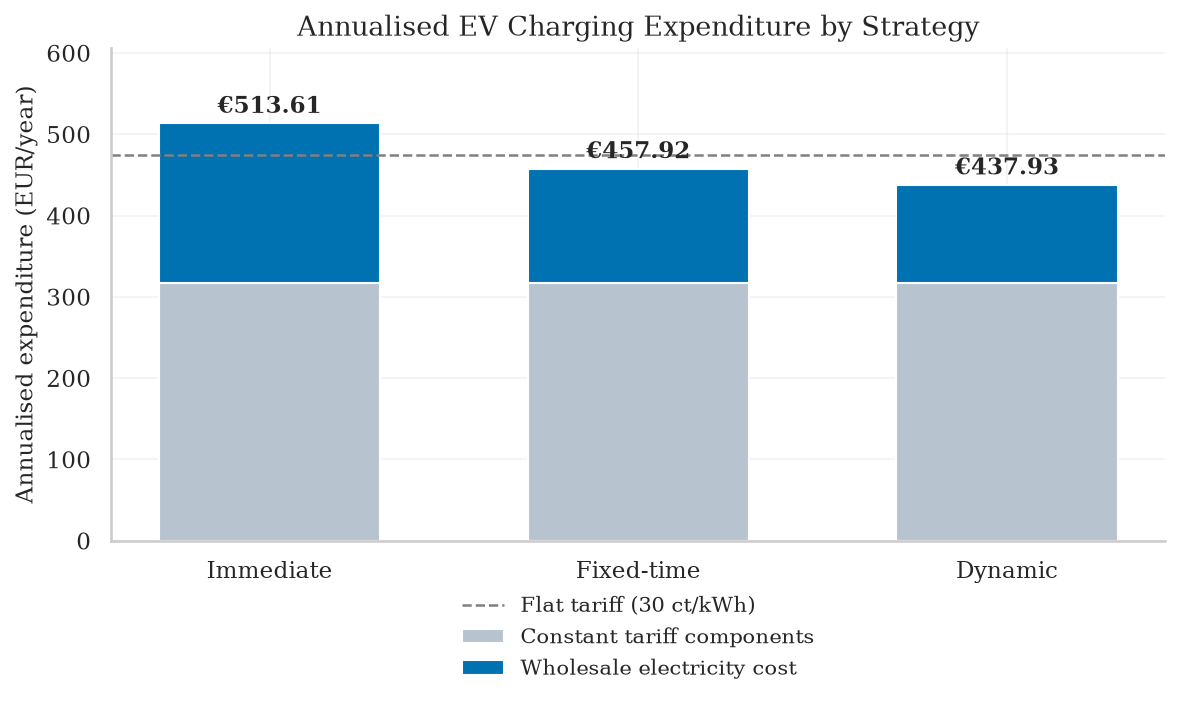

In [39]:
# Calculate annual constant tariff charges
constant_cost = (
    ANNUAL_HOME_GRID_ENERGY_KWH
    * CONSTANT_CHARGES_EUR_KWH
)

spot_costs = annual_summary[
    "annual_spot_cost_eur"
]

retail_costs = annual_summary[
    "annual_retail_cost_eur"
]

# Create figure
fig, ax = plt.subplots(figsize=(8, 5))

x = np.arange(len(strategies))

# Constant tariff components
ax.bar(
    x,
    [constant_cost] * len(strategies),
    width=0.6,
    color="#B7C4CF",
    label="Constant tariff components"
)

# Wholesale electricity component
ax.bar(
    x,
    spot_costs,
    bottom=constant_cost,
    width=0.6,
    color="#0072B2",
    label="Wholesale electricity cost"
)

# Display total expenditure
for i, cost in enumerate(retail_costs):

    ax.annotate(
        f"€{cost:.2f}",
        xy=(i, cost),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontweight="bold"
    )

# Flat tariff reference
ax.axhline(
    ANNUAL_HOME_GRID_ENERGY_KWH
    * FLAT_TARIFF_EUR_KWH,
    linestyle="--",
    color="grey",
    linewidth=1.2,
    label="Flat tariff (30 ct/kWh)"
)

ax.set_title(
    "Annualised EV Charging Expenditure by Strategy"
)

ax.set_ylabel("Annualised expenditure (EUR/year)")
ax.set_xticks(x)
ax.set_xticklabels(strategies)
ax.margins(y=0.18)

ax.legend(
    frameon=False,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.32)
)

fig.tight_layout()

save_figure(fig, "07_annual_charging_expenditure")

plt.show()

#### 9.3 Seasonal economic savings

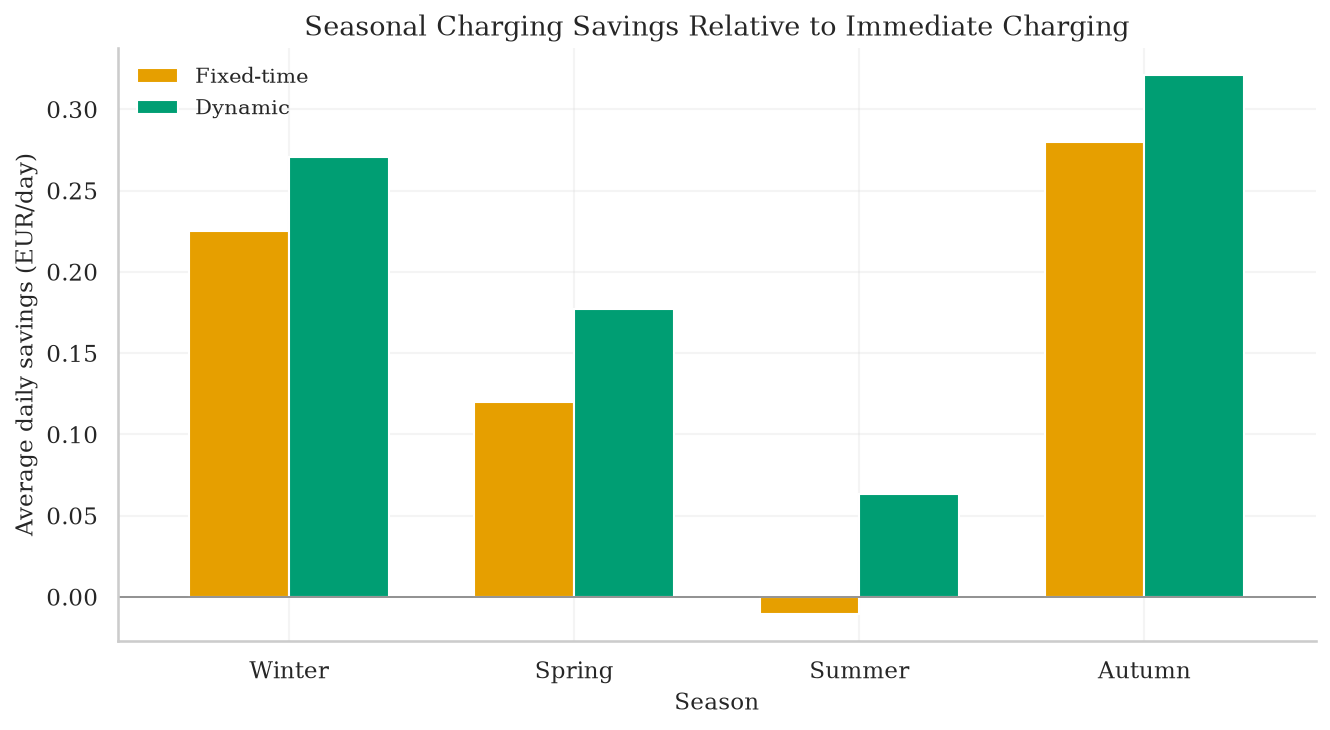

In [40]:
# Prepare seasonal daily savings
plot_data = seasonal_savings[
    [
        "Fixed-time savings (EUR/day)",
        "Dynamic savings (EUR/day)"
    ]
].copy()

plot_data.columns = [
    "Fixed-time",
    "Dynamic"
]

# Create grouped bar chart
fig, ax = plt.subplots(figsize=(9, 5))

plot_data.plot(
    kind="bar",
    color=[
        strategy_colors["Fixed-time"],
        strategy_colors["Dynamic"]
    ],
    width=0.7,
    ax=ax
)

ax.axhline(
    0,
    color="grey",
    linewidth=0.8
)

ax.set_title(
    "Seasonal Charging Savings Relative to Immediate Charging"
)

ax.set_xlabel("Season")
ax.set_ylabel("Average daily savings (EUR/day)")

ax.tick_params(
    axis="x",
    rotation=0
)

ax.legend(frameon=False)

fig.tight_layout()

save_figure(fig, "08_seasonal_charging_savings")

plt.show()

#### 9.4 comulative charging savings

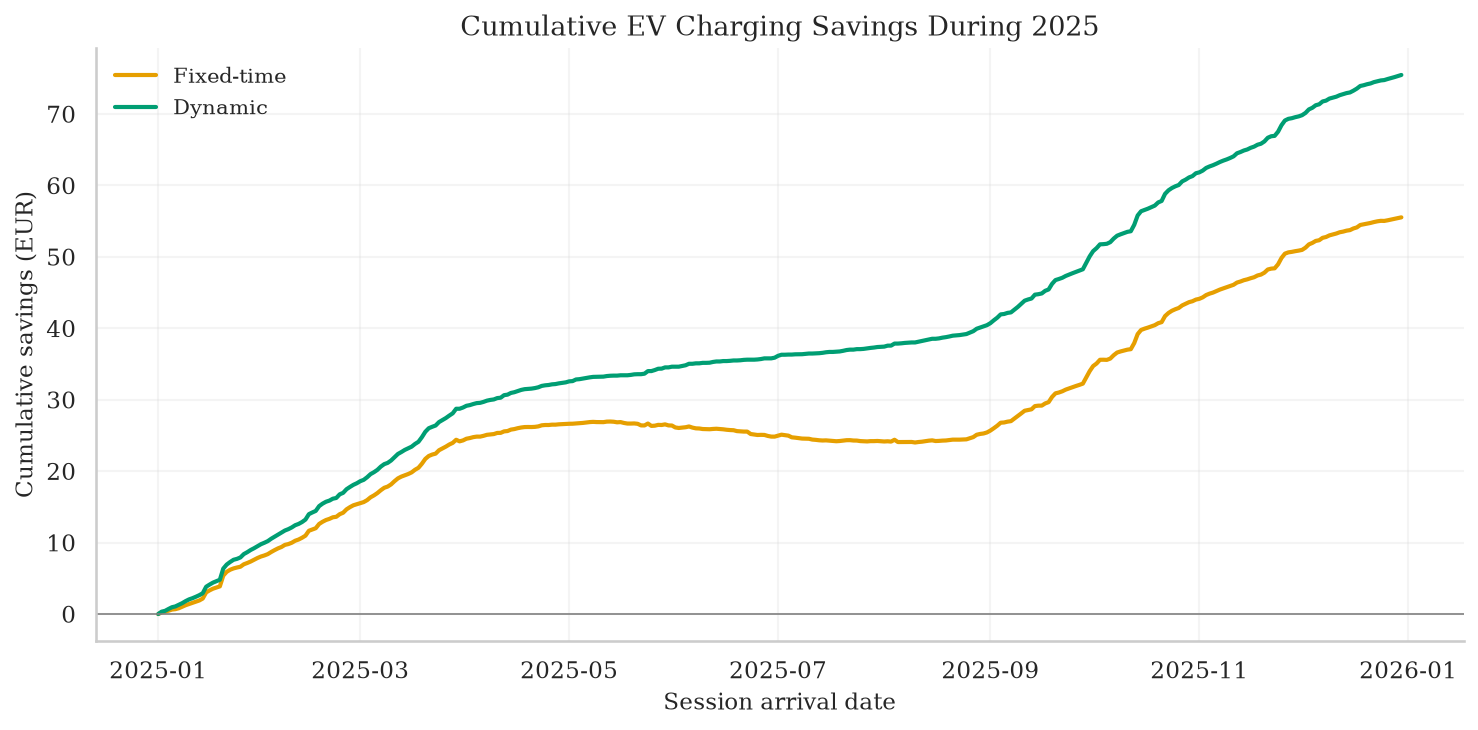

In [41]:
# Prepare chronological daily savings
cumulative_savings = daily_strategy_costs[
    [
        "Fixed-time savings",
        "Dynamic savings"
    ]
].copy()

cumulative_savings.index = pd.to_datetime(
    cumulative_savings.index
)

cumulative_savings = (
    cumulative_savings.sort_index().cumsum()
)

# Create figure
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    cumulative_savings.index,
    cumulative_savings["Fixed-time savings"],
    color=strategy_colors["Fixed-time"],
    linewidth=2,
    label="Fixed-time"
)

ax.plot(
    cumulative_savings.index,
    cumulative_savings["Dynamic savings"],
    color=strategy_colors["Dynamic"],
    linewidth=2,
    label="Dynamic"
)

ax.axhline(
    0,
    linewidth=0.8,
    color="grey"
)

ax.set_title(
    "Cumulative EV Charging Savings During 2025"
)

ax.set_xlabel("Session arrival date")
ax.set_ylabel("Cumulative savings (EUR)")

ax.legend(frameon=False)

fig.tight_layout()

save_figure(fig, "09_cumulative_charging_savings")

plt.show()

## 10. Export of Simulation Results

Interval-level charging schedules, session-level
electricity expenditure, annualised economic results
and seasonal performance indicators are exported.

The exported datasets facilitate reproducibility,
subsequent sensitivity analyses and the integration
of quantitative evidence into the reflection paper.

Full numerical precision is preserved in the
exported results.

In [42]:
# Export model parameters
parameters.to_csv(
    tables_dir / "charging_model_parameters.csv",
    header=True
)

# Export interval-level charging schedules
simulation.to_csv(
    processed_dir / "charging_simulation_2025.csv",
    index=False
)

# Export session-level results
session_summary.to_csv(
    processed_dir / "charging_session_results_2025.csv",
    index=False
)

# Export annual economic results
annual_summary.to_csv(
    tables_dir / "annual_charging_results.csv"
)

# Export incremental dynamic value
incremental_summary.to_csv(
    tables_dir / "incremental_dynamic_value.csv",
    header=True
)

# Export seasonal results
seasonal_results.to_csv(
    tables_dir / "seasonal_charging_results.csv",
    index=False
)

seasonal_savings.to_csv(
    tables_dir / "seasonal_charging_savings.csv"
)

# Export strategy performance frequencies
frequency_summary_pct.to_csv(
    tables_dir / "charging_strategy_frequency.csv"
)

print("All simulation results successfully exported.")

All simulation results successfully exported.


## 11. Economic Interpretation and Key Findings

### 11.1 Annual Economic Benefits

The simulation compares three charging strategies across 364 complete overnight charging sessions using historical German–Luxembourg day-ahead electricity prices for 2025.

Annualised residential electricity consumption amounts to 1,584 kWh for each strategy. Under the illustrative dynamic residential tariff, annualised charging expenditure amounts to EUR 513.61 for immediate charging, EUR 457.92 for fixed-time charging and EUR 437.93 for dynamic smart charging.

Dynamic charging therefore reduces annualised electricity expenditure by EUR 75.68, corresponding to 14.73% relative to immediate charging.

All strategies deliver identical electricity quantities and achieve the same scheduled departure state of charge. The economic benefits consequently arise from the temporal reallocation of electricity consumption.

### 11.2 Wholesale and Retail Savings

Dynamic charging reduces wholesale electricity expenditure by 38.45%, whereas the corresponding reduction in illustrative residential expenditure amounts to 14.73%.

This difference arises from the presence of time-invariant tariff components, which account for EUR 316.80 annually under the assumed tariff.

Since the total electricity quantity remains identical across strategies, constant per-kWh charges do not alter absolute savings but reduce their proportional contribution to total electricity expenditure.

### 11.3 Incremental Value of Dynamic Optimisation

Fixed-time charging generates annualised savings of EUR 55.69, capturing 73.59% of the economic benefits available through dynamic overnight charging.

The incremental economic value of dynamic optimisation relative to fixed-time charging amounts to EUR 19.99 annually, or approximately EUR 1.67 per month.

This finding illustrates the importance of distinguishing the total economic benefits of charging flexibility from the additional value created by more sophisticated optimisation technologies.

Under the model assumptions, additional service fees exceeding this incremental value would eliminate the financial advantage of dynamic charging over fixed-time charging, unless the service provides other economic or non-economic benefits.

### 11.4 Seasonal Economic Performance

The economic benefits of smart charging differ considerably across seasons.

| Season | Fixed-time savings (EUR/day) | Dynamic savings (EUR/day) | Dynamic retail savings (%) |
|---|---:|---:|---:|
| Winter | 0.2250 | 0.2709 | 18.05 |
| Spring | 0.1198 | 0.1773 | 12.78 |
| Summer | −0.0105 | 0.0632 | 4.98 |
| Autumn | 0.2797 | 0.3212 | 21.78 |

Despite relatively large daily electricity price spreads during summer, achievable overnight charging savings are lowest during this season.

This finding is consistent with the exploratory analysis, which identifies that 97.83% of weighted daily minimum-price opportunities occur during daytime in summer.

The results suggest that the economic benefits of charging flexibility depend on the temporal alignment between vehicle availability and electricity price opportunities.

### 11.5 Consistency of Economic Benefits

Fixed-time charging reduces electricity expenditure relative to immediate charging in 287 of the 364 simulated sessions (78.85%), while increasing costs in the remaining 77 sessions (21.15%).

Dynamic charging generates strictly positive savings in 337 sessions (92.58%) and equivalent costs in 27 sessions (7.42%).

The absence of negative savings under dynamic charging follows from the cost-minimisation objective and the common feasible charging set.

### 11.6 Implications for Further Analysis

The results motivate three subsequent sensitivity experiments:

1. Varying the duration of available charging windows to estimate the marginal economic value of flexibility.
2. Comparing equally long charging windows occurring at different times of the day.
3. Examining the sensitivity of economic outcomes to electricity tariff components, charging power and energy requirements.

### 11.7 Limitations

The simulation represents a hypothetical EV owner with constant daily energy requirements, fixed overnight charging availability and identical scheduled departure state-of-charge requirements.

Interday battery optimisation, unexpected mobility requirements, household photovoltaic generation, bidirectional charging and time-variable network charges are excluded.

The residential tariff is illustrative rather than an observed commercial electricity contract. Technology costs, service fees and consumer discomfort costs are not included in the main expenditure estimates.

Hourly average prices are used throughout 2025, including the period following the introduction of quarter-hourly day-ahead market products.

Annualised results are extrapolated from 364 complete overnight charging sessions. They represent conditional simulated expenditure rather than observed household electricity bills.

**Source:** Own simulation based on historical Germany–Luxembourg day-ahead electricity prices retrieved from the Fraunhofer ISE Energy-Ch